# 03 - Honest evaluation and risk bands (Day 4)
Everything below is reproducible from this notebook.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / 'src').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 50); pd.set_option('display.max_colwidth', 120)
from cortexhr import config as C, data_loading as D, audit as A, features as F, modeling as M, evaluation as E, reporting as R, runs

In [2]:
ev = runs.run_evaluation(write=False)
ev['metrics'].round(3).T

                                               0                          1                                                                2
evaluation         Training out-of-fold (5-fold)  Held-out test (used once)  Held-out test @ threshold 0.772 (top-10% cut from training OOF)
n                                           1906                        477                                                              477
positives                                    279                         70                                                               70
base_rate                                  0.146                      0.147                                                            0.147
roc_auc                                    0.697                      0.682                                                            0.682
pr_auc                                     0.294                      0.321                                                            0.321
threshold    

**ROC-AUC**: chance a random leaver outranks a random stayer. **PR-AUC**: purity of the flagged list when few people leave (compare with the base rate). **Top-10%**: review only the highest-scored 10%; ties broken by row position.

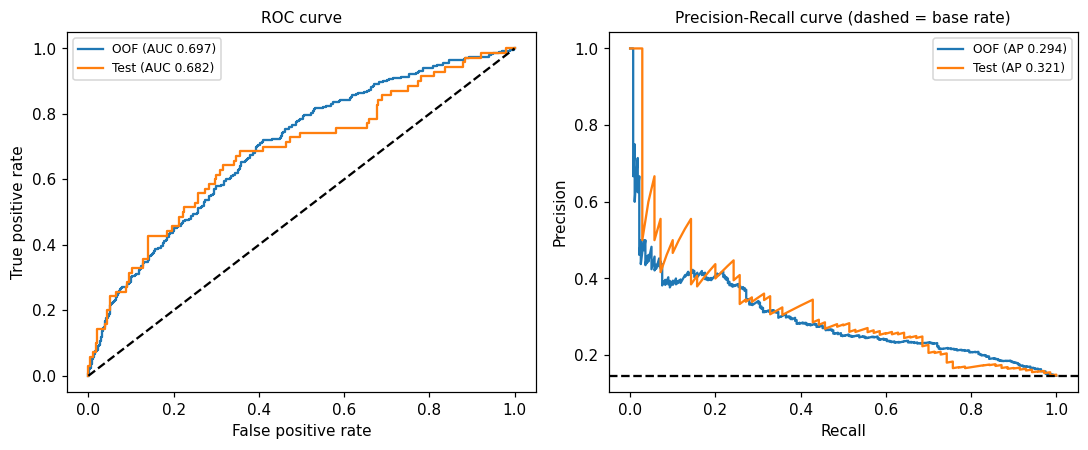

In [3]:
S = ev['state']; E.plot_roc_pr({'OOF': (S['ytr'], ev['oof']), 'Test': (S['yte'], ev['p_test'])});

## Calibration (fitted on training OOF only, never on test labels)

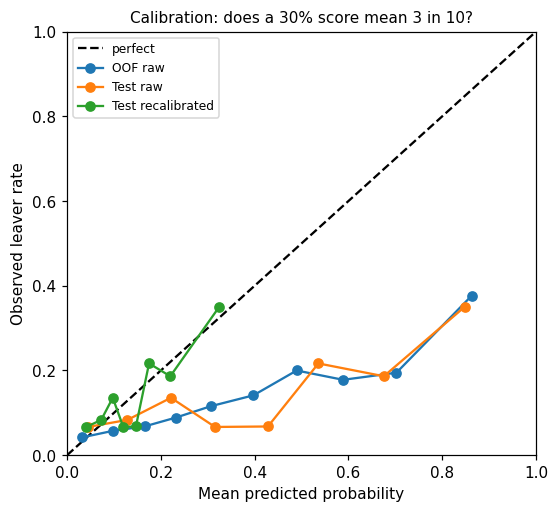

In [4]:
E.plot_calibration(ev['calibration']);

In [5]:
print(ev['brier'])

{'test_raw': 0.21308497475545887, 'test_recalibrated': 0.1165020698841042, 'mean_pred_test_raw': 0.39952010966575296, 'mean_pred_test_recal': 0.1496514141169653, 'base_rate_test': 0.14675052410901468}


## Risk bands: High = top 10%, Medium = next 20%, Low = rest

In [6]:
for k, t in ev['band_summary'].items():
    print(k); print(t.round(2).to_string())

Training OOF
     band  employees  leavers  share_of_employees_pct  leaver_rate_pct  share_of_all_leavers_pct  lift_vs_base_rate
0    High        191       72                   10.02            37.70                     25.81               2.58
1  Medium        381       71                   19.99            18.64                     25.45               1.27
2     Low       1334      136                   69.99            10.19                     48.75               0.70
Held-out test
     band  employees  leavers  share_of_employees_pct  leaver_rate_pct  share_of_all_leavers_pct  lift_vs_base_rate
0    High         48       18                   10.06            37.50                     25.71               2.56
1  Medium         96       21                   20.13            21.88                     30.00               1.49
2     Low        333       31                   69.81             9.31                     44.29               0.63


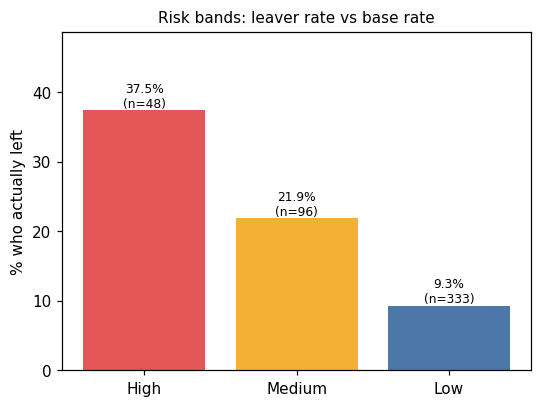

In [7]:
E.plot_bands(ev['band_summary']['Held-out test']);

## Lift / gains vs random selection

In [8]:
ev['gains']['Held-out test'].round(2)

   top_pct    k  leavers_captured  capture_rate_pct  random_capture_pct  lift
0     10.0   48                18             25.71                10.0  2.57
1     20.0   96                30             42.86                20.0  2.14
2     30.0  144                39             55.71                30.0  1.86
3     40.0  191                47             67.14                40.0  1.68
4     50.0  239                50             71.43                50.0  1.43
5     60.0  287                52             74.29                60.0  1.24
6     70.0  334                58             82.86                70.0  1.18
7     80.0  382                64             91.43                80.0  1.14
8     90.0  430                68             97.14                90.0  1.08
9    100.0  477                70            100.00               100.0  1.00

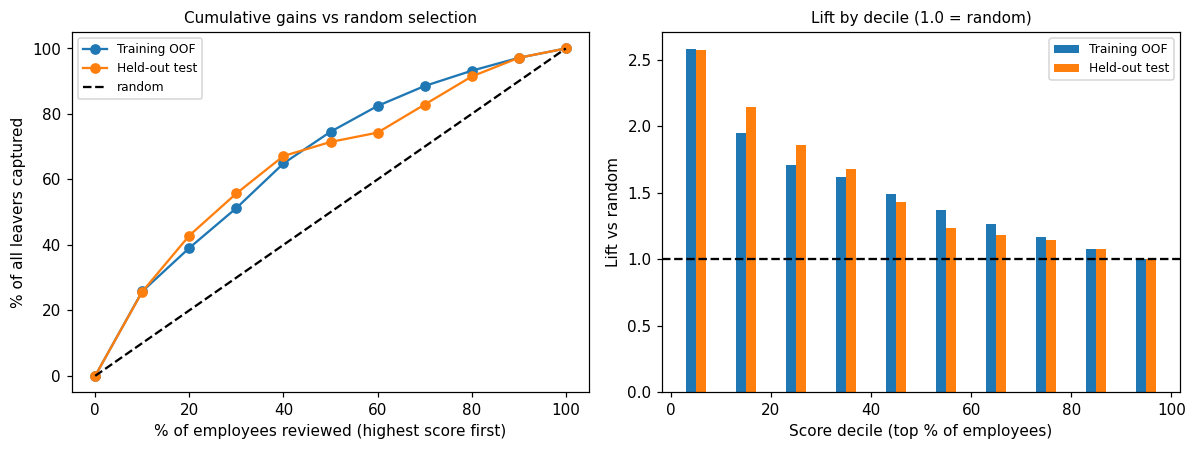

In [9]:
E.plot_gains_lift(ev['gains']);

Manager note: `reports/manager_summary.md`. Full report: `reports/model_evaluation_report.md`.

In [10]:
print(open(C.project_root() / 'reports' / 'manager_summary.md').read())

# CortexHR attrition score: one-page note for managers

**What the score is.** For each employee the model estimates how likely they are to leave in the next 12 months, based on pay position, raises, engagement, workload, tenure and recent attendance. We rank everyone and group them: **High** = top 10% of scores, **Medium** = next 20%, **Low** = the remaining 70%.

**How well it works (held-out data, 477 employees, 70 actual leavers).**
- Overall 14.7% left. In the **High** band 38% left (18 of 48), versus 9% in the **Low** band.
- The High band holds **26%** of all leavers (random picking would give 10%); High + Medium hold 56%.
- Ranking quality is moderate: ROC-AUC 0.68, PR-AUC 0.32. It is useful for prioritising conversations, not for predicting individuals.

**What the score is NOT.**
- Not a decision. It does not know why someone might leave, and most High-band people (62%) did **not** leave.
- Not a probability you can quote: raw scores are inflated by design (0.40 average vs 0.